<a href="https://colab.research.google.com/github/Deshawa77/pusl3123-a1/blob/main/Exercise4_Width_Depth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, sys, random, json, time, copy
PROJECT = "/content/drive/MyDrive/pusl3123-a1"
assert os.path.isdir(PROJECT), "Create the pusl3123-a1 folder in your own Google Drive first."
os.chdir(PROJECT)
assert os.path.exists("split.npy"), "Upload split.npy into the folder."

import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

import hashlib
print("split.npy md5:", hashlib.md5(open("split.npy", "rb").read()).hexdigest())

Mounted at /content/drive
device: cuda | torch 2.14.1+cu130
split.npy md5: cce9ce35fbbe01a0d96acd716fff84c5


In [2]:
MEAN = (0.49181848764419556, 0.4826730489730835, 0.44718557596206665)
STD  = (0.246906116604805, 0.2434273362159729, 0.2615409195423126)

base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
R = "/content/data"
full_clean = torchvision.datasets.CIFAR10(R, train=True,  download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10(R, train=False, download=True, transform=base_tf)

perm = np.load("split.npy")
train_idx, val_idx = perm[:45000].tolist(), perm[45000:].tolist()
assert len(set(train_idx) & set(val_idx)) == 0

BATCH = 128
def make_train_loader(seed):
    g = torch.Generator(); g.manual_seed(seed)          # shuffle order depends only on the run seed
    return DataLoader(Subset(full_clean, train_idx), batch_size=BATCH, shuffle=True, generator=g)

train_loader_eval = DataLoader(Subset(full_clean, train_idx), batch_size=512, shuffle=False)
val_loader  = DataLoader(Subset(full_clean, val_idx), batch_size=512, shuffle=False)
test_loader = DataLoader(test_set, batch_size=512, shuffle=False)       # final scoring only
print(len(train_idx), len(val_idx), len(test_set))

100%|██████████| 170M/170M [14:42<00:00, 193kB/s]


45000 5000 10000


In [4]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def count_macs(model):
    """Multiply-accumulates for one 32x32 image (conv + linear layers). Parameters != compute."""
    macs = [0]
    def conv_hook(m, i, o): macs[0] += o.shape[2] * o.shape[3] * m.out_channels * m.in_channels * m.kernel_size[0] * m.kernel_size[1]
    def lin_hook(m, i, o):  macs[0] += m.in_features * m.out_features
    hs  = [m.register_forward_hook(conv_hook) for m in model.modules() if isinstance(m, nn.Conv2d)]
    hs += [m.register_forward_hook(lin_hook)  for m in model.modules() if isinstance(m, nn.Linear)]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device))
    for h in hs: h.remove()
    return macs[0]

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += crit(out, yb).item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item(); n += xb.size(0)
    return total / n, correct / n

def fit_both(model, train_loader, val_loader, epochs=30, lr=1e-3, name="run", every=5):
    """Adam / lr / epochs / best-validation-loss rule identical to the other exercises.
    Returns best-validation weights AND final-epoch weights."""
    model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"]}
    best_val, best_state, best_epoch = float("inf"), None, -1
    for ep in range(epochs):
        t0 = time.time(); model.train()
        run, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb); loss = crit(out, yb)
            loss.backward(); opt.step()
            run += loss.item() * xb.size(0); correct += (out.argmax(1) == yb).sum().item(); n += xb.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va); hist["epoch_time"].append(time.time() - t0)
        if vl < best_val:
            best_val, best_epoch = vl, ep; best_state = copy.deepcopy(model.state_dict())
        if (ep + 1) % every == 0 or ep == 0:
            print(f"[{name}] ep {ep+1:02d} | train {run/n:.3f}/{correct/n:.3f} | val {vl:.3f}/{va:.3f}")
    last_state = copy.deepcopy(model.state_dict())
    hist.update(best_epoch=best_epoch, params=count_params(model), name=name)
    return hist, best_state, last_state

In [5]:
def make_cnn(channels, pool_after):
    """channels: kernels per conv layer. pool_after: indices of conv layers followed by 2x2 max-pool.
    Every variant uses exactly two pools, so the final feature map is always 8x8."""
    layers, c_in, size = [], 3, 32
    for i, c in enumerate(channels):
        layers += [nn.Conv2d(c_in, c, 3, padding=1), nn.ReLU()]
        c_in = c
        if i in pool_after:
            layers.append(nn.MaxPool2d(2)); size //= 2
    assert size == 8, "keep exactly two pooling layers"
    return nn.Sequential(*layers, nn.Flatten(), nn.Linear(c_in * size * size, 10))

ARCHS = {
    # width sweep: depth fixed at 2 conv layers
    "w1": dict(channels=[16, 32],  pool_after={0, 1}, sweep="width", label="16-32"),
    "w2": dict(channels=[32, 64],  pool_after={0, 1}, sweep="width", label="32-64"),
    "w3": dict(channels=[64, 128], pool_after={0, 1}, sweep="width", label="64-128"),
    # depth sweep: width fixed at 32 kernels per layer
    "d2": dict(channels=[32] * 2,  pool_after={0, 1}, sweep="depth", label="2 conv"),
    "d3": dict(channels=[32] * 3,  pool_after={1, 2}, sweep="depth", label="3 conv"),
    "d4": dict(channels=[32] * 4,  pool_after={1, 3}, sweep="depth", label="4 conv"),
}
EXPECTED = {"w1": 25578, "w2": 60362, "w3": 157578, "d2": 30634, "d3": 39882, "d4": 49130}

set_seed(42)
for a, spec in ARCHS.items():
    m = make_cnn(spec["channels"], spec["pool_after"]).to(device)
    assert m(torch.zeros(2, 3, 32, 32, device=device)).shape == (2, 10)
    assert count_params(m) == EXPECTED[a], (a, count_params(m))
    print(f"{a}: params {count_params(m):>8,} | MACs {count_macs(m)/1e6:6.2f} M | {spec['label']}")

w1: params   25,578 | MACs   1.64 M | 16-32
w2: params   60,362 | MACs   5.64 M | 32-64
w3: params  157,578 | MACs  20.73 M | 64-128
d2: params   30,634 | MACs   3.26 M | 2 conv
d3: params   39,882 | MACs  12.70 M | 3 conv
d4: params   49,130 | MACs  15.06 M | 4 conv


In [6]:
def snapshot(model, state):
    model.load_state_dict(state)
    tl, ta = evaluate(model, train_loader_eval)               # clean train set, eval mode
    vl, va = evaluate(model, val_loader)
    _, te  = evaluate(model, test_loader)                     # reported only; nothing is chosen with it
    return dict(train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va, test_acc=te, gap=ta - te)

def run_arch(arch, seed, epochs=30):
    name = f"ex4_{arch}_s{seed}"
    path = f"results/{name}.json"
    if os.path.exists(path):
        return json.load(open(path))
    set_seed(seed)
    spec = ARCHS[arch]
    model = make_cnn(spec["channels"], spec["pool_after"])
    hist, best_state, last_state = fit_both(model, make_train_loader(seed), val_loader, epochs, name=name)
    res = dict(arch=arch, seed=seed, params=count_params(model), macs=count_macs(model), history=hist,
               best_epoch=hist["best_epoch"] + 1,
               best=snapshot(model, best_state), last=snapshot(model, last_state))
    json.dump(res, open(path, "w"))
    return res

In [7]:
SEEDS = [42]                       # later extend to [42, 43, 44] for mean ± std
results = {(a, s): run_arch(a, s) for s in SEEDS for a in ARCHS}

# cross-check: w2 is the Exercise 2 CNN, so it should reproduce Ex2/Ex3 baseline numbers closely
print("w2 best epoch:", results[("w2", 42)]["best_epoch"],
      "| val acc at best: %.4f" % results[("w2", 42)]["best"]["val_acc"])

[ex4_w1_s42] ep 01 | train 1.484/0.474 | val 1.271/0.556
[ex4_w1_s42] ep 05 | train 0.926/0.678 | val 0.976/0.674
[ex4_w1_s42] ep 10 | train 0.772/0.732 | val 0.946/0.685
[ex4_w1_s42] ep 15 | train 0.684/0.763 | val 0.936/0.694
[ex4_w1_s42] ep 20 | train 0.629/0.779 | val 0.963/0.685
[ex4_w1_s42] ep 25 | train 0.583/0.797 | val 1.004/0.682
[ex4_w1_s42] ep 30 | train 0.549/0.806 | val 1.036/0.684
[ex4_w2_s42] ep 01 | train 1.402/0.503 | val 1.145/0.606
[ex4_w2_s42] ep 05 | train 0.756/0.740 | val 0.875/0.710
[ex4_w2_s42] ep 10 | train 0.543/0.814 | val 0.897/0.715
[ex4_w2_s42] ep 15 | train 0.411/0.857 | val 0.987/0.711
[ex4_w2_s42] ep 20 | train 0.314/0.889 | val 1.122/0.708
[ex4_w2_s42] ep 25 | train 0.239/0.917 | val 1.352/0.695
[ex4_w2_s42] ep 30 | train 0.188/0.934 | val 1.515/0.699
[ex4_w3_s42] ep 01 | train 1.330/0.530 | val 1.060/0.631
[ex4_w3_s42] ep 05 | train 0.656/0.774 | val 0.818/0.727
[ex4_w3_s42] ep 10 | train 0.399/0.862 | val 0.929/0.726
[ex4_w3_s42] ep 15 | train 0.24

In [8]:
def fmt(v, scale=100, d=2):
    v = np.array(v) * scale
    return f"{v.mean():.{d}f}" + (f" ± {v.std(ddof=1):.{d}f}" if len(v) > 1 else "")

def table(ckpt):
    rows = []
    for a, spec in ARCHS.items():
        R_ = [results[(a, s)] for s in SEEDS]
        rows.append({"Arch": a, "Sweep": spec["sweep"], "Setting": spec["label"],
                     "Params": R_[0]["params"], "MMACs": round(R_[0]["macs"] / 1e6, 2),
                     "BestEpoch": round(np.mean([r["best_epoch"] for r in R_]), 1),
                     "TrainLoss": fmt([r[ckpt]["train_loss"] for r in R_], 1, 3),
                     "TrainAcc %": fmt([r[ckpt]["train_acc"] for r in R_]),
                     "Val %": fmt([r[ckpt]["val_acc"] for r in R_]),
                     "Test %": fmt([r[ckpt]["test_acc"] for r in R_]),
                     "s/epoch": round(np.mean([np.mean(r["history"]["epoch_time"]) for r in R_]), 1)})
    return pd.DataFrame(rows)

t_best, t_last = table("best"), table("last")
print("Best-validation-loss checkpoint (primary):\n", t_best.to_string(index=False))
print("\nFinal-epoch weights (shows how far each model overfits):\n", t_last.to_string(index=False))
t_best.to_csv("results/ex4_table_best.csv", index=False); t_last.to_csv("results/ex4_table_last.csv", index=False)

Best-validation-loss checkpoint (primary):
 Arch Sweep Setting  Params  MMACs  BestEpoch TrainLoss TrainAcc % Val % Test %  s/epoch
  w1 width   16-32   25578   1.64       15.0     0.628      78.45 69.38  68.81     12.1
  w2 width   32-64   60362   5.64        8.0     0.535      82.05 72.10  71.64     12.8
  w3 width  64-128  157578  20.73        5.0     0.550      81.83 72.70  72.43     14.6
  d2 depth  2 conv   30634   3.26       15.0     0.559      80.79 71.20  70.65     11.8
  d3 depth  3 conv   39882  12.70        8.0     0.595      79.50 72.74  71.75     14.7
  d4 depth  4 conv   49130  15.06        8.0     0.566      80.40 73.64  72.78     15.0

Final-epoch weights (shows how far each model overfits):
 Arch Sweep Setting  Params  MMACs  BestEpoch TrainLoss TrainAcc % Val % Test %  s/epoch
  w1 width   16-32   25578   1.64       15.0     0.514      82.21 68.44  67.89     12.1
  w2 width   32-64   60362   5.64        8.0     0.148      95.10 69.92  69.48     12.8
  w3 width  64-12

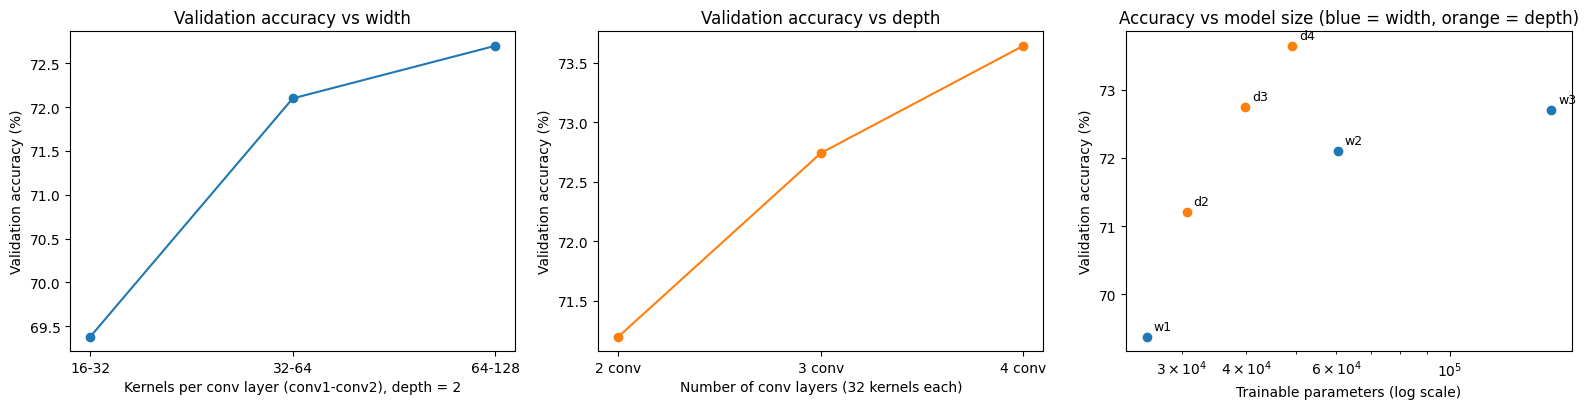

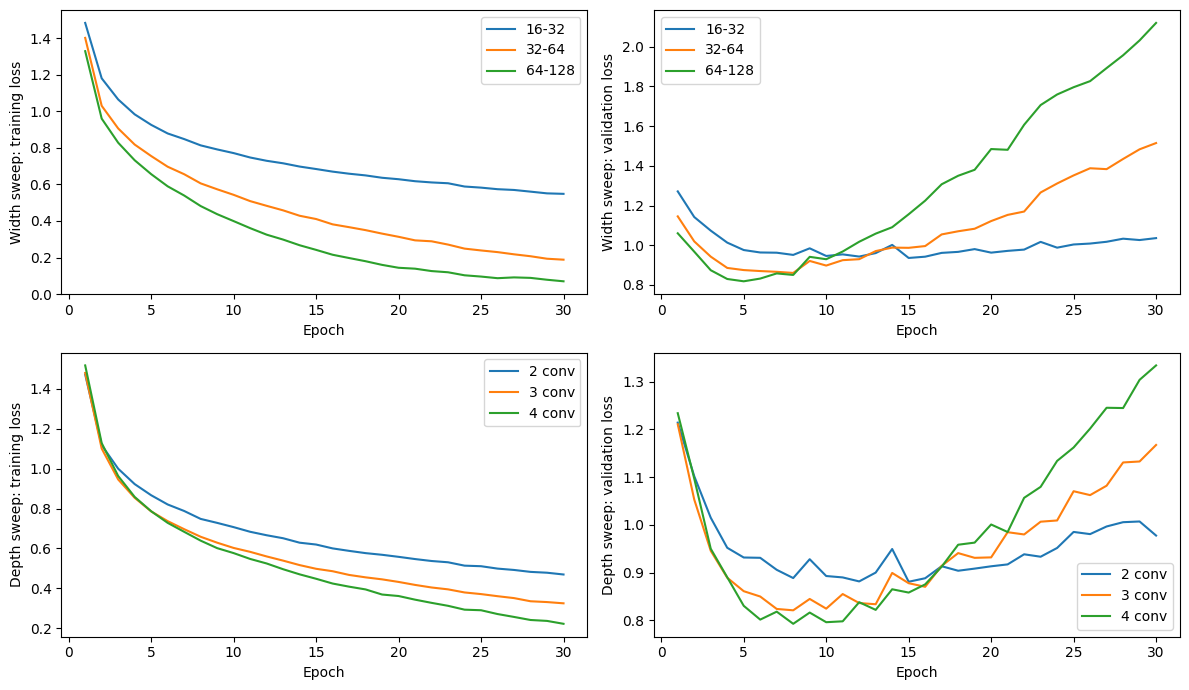

In [9]:
COL = {"width": "tab:blue", "depth": "tab:orange"}

def agg(a, ckpt, key, scale=100):
    v = np.array([results[(a, s)][ckpt][key] for s in SEEDS]) * scale
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
xlabels = {"width": "Kernels per conv layer (conv1-conv2), depth = 2",
           "depth": "Number of conv layers (32 kernels each)"}
for a_ax, sweep in zip(ax[:2], ["width", "depth"]):
    names = [a for a in ARCHS if ARCHS[a]["sweep"] == sweep]
    m = [agg(a, "best", "val_acc") for a in names]
    a_ax.errorbar(range(3), [x[0] for x in m], yerr=[x[1] for x in m], marker="o", capsize=3, color=COL[sweep])
    a_ax.set_xticks(range(3)); a_ax.set_xticklabels([ARCHS[a]["label"] for a in names])
    a_ax.set_xlabel(xlabels[sweep]); a_ax.set_ylabel("Validation accuracy (%)"); a_ax.set_title(f"Validation accuracy vs {sweep}")
for a, spec in ARCHS.items():
    m, e = agg(a, "best", "val_acc")
    ax[2].errorbar(results[(a, SEEDS[0])]["params"], m, yerr=e, marker="o", capsize=3, color=COL[spec["sweep"]])
    ax[2].annotate(a, (results[(a, SEEDS[0])]["params"], m), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax[2].set_xscale("log"); ax[2].set_xlabel("Trainable parameters (log scale)")
ax[2].set_ylabel("Validation accuracy (%)"); ax[2].set_title("Accuracy vs model size (blue = width, orange = depth)")
plt.tight_layout(); plt.savefig("figures/ex4_accuracy_summary.png", dpi=200); plt.show()

def mean_curve(a, key):
    return np.mean([results[(a, s)]["history"][key] for s in SEEDS], axis=0)

ep = range(1, 31)
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for row, sweep in enumerate(["width", "depth"]):
    for a in [a for a in ARCHS if ARCHS[a]["sweep"] == sweep]:
        ax[row, 0].plot(ep, mean_curve(a, "train_loss"), label=ARCHS[a]["label"])
        ax[row, 1].plot(ep, mean_curve(a, "val_loss"),   label=ARCHS[a]["label"])
    ax[row, 0].set_ylabel(f"{sweep.capitalize()} sweep: training loss"); ax[row, 1].set_ylabel(f"{sweep.capitalize()} sweep: validation loss")
    for c in range(2): ax[row, c].set_xlabel("Epoch"); ax[row, c].legend()
plt.tight_layout(); plt.savefig("figures/ex4_curves.png", dpi=200); plt.show()

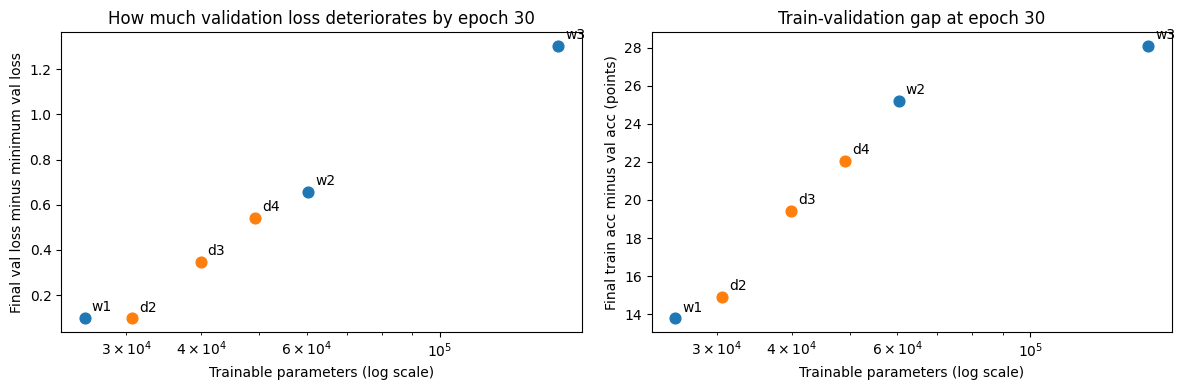

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, spec in ARCHS.items():
    P = results[(a, SEEDS[0])]["params"]
    pen = np.mean([results[(a, s)]["history"]["val_loss"][-1] - min(results[(a, s)]["history"]["val_loss"]) for s in SEEDS])
    gap = np.mean([results[(a, s)]["last"]["train_acc"] - results[(a, s)]["last"]["val_acc"] for s in SEEDS]) * 100
    for a_ax, y in zip(ax, [pen, gap]):
        a_ax.scatter(P, y, color=COL[spec["sweep"]], s=60); a_ax.annotate(a, (P, y), textcoords="offset points", xytext=(5, 5))
ax[0].set_ylabel("Final val loss minus minimum val loss"); ax[1].set_ylabel("Final train acc minus val acc (points)")
for a_ax in ax: a_ax.set_xscale("log"); a_ax.set_xlabel("Trainable parameters (log scale)")
ax[0].set_title("How much validation loss deteriorates by epoch 30"); ax[1].set_title("Train-validation gap at epoch 30")
plt.tight_layout(); plt.savefig("figures/ex4_overfitting.png", dpi=200); plt.show()